# Import packages

In [8]:
!pip -q install xgboost joblib

import os
import glob
import warnings
import numpy as np
import pandas as pd
import joblib

from scipy.signal import resample_poly
from scipy.stats import skew, kurtosis

from IPython.display import display

warnings.filterwarnings("ignore")

# Sampling rates used during WESAD training
BVP_FS = 64
ACC_FS = 32

# Your wearable recording rate
OWN_FS = 100

# Window configuration must match WESAD
WINDOW_SEC = 10

print("Libraries imported successfully.")

Libraries imported successfully.


# Upload these five files from your computer:
1. WESAD_9_trained_models_v2.joblib
2. PPG_ACC_Resting.txt
3. PPG_ACC_Math.txt
4. PPG_ACC_Speaking.txt
5. PPG_ACC_Walking.txt

In [9]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving WESAD_9_trained_models_v2.joblib to WESAD_9_trained_models_v2.joblib

Uploaded files:
WESAD_9_trained_models_v2.joblib


In [10]:
uploaded = files.upload()

Saving PPG_ACC_Math.txt to PPG_ACC_Math (1).txt
Saving PPG_ACC_Resting.txt to PPG_ACC_Resting (1).txt
Saving PPG_ACC_Speaking.txt to PPG_ACC_Speaking (1).txt
Saving PPG_ACC_Walking.txt to PPG_ACC_Walking (1).txt


# load the models:

In [11]:
# ============================================================
# Load frozen WESAD models
# ============================================================

MODEL_PATH = "/content/WESAD_9_trained_models_v2.joblib"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Please upload WESAD_9_trained_models_v2.joblib"
    )

model_bundle = joblib.load(MODEL_PATH)

final_models = model_bundle["models"]

print("Model bundle loaded successfully.")

print("Feature version:",
      model_bundle["feature_version"])

print("Training participants:",
      model_bundle["number_of_subjects"])

print("Training windows:",
      model_bundle["number_of_training_windows"])

print("\nAvailable models:")

for model_name in final_models:
    print(model_name)

if len(final_models) != 9:
    raise ValueError(
        f"Expected 9 models, but found {len(final_models)}"
    )

Model bundle loaded successfully.
Feature version: v2
Training participants: 15
Training windows: 2733

Available models:
BVP_only_RF
BVP_only_SVM
BVP_only_XGB
ACC_only_RF
ACC_only_SVM
ACC_only_XGB
BVP_ACC_combined_RF
BVP_ACC_combined_SVM
BVP_ACC_combined_XGB


In [12]:
# ============================================================
# Recording file configuration
# ============================================================

RECORDINGS = {
    "Resting": "/content/PPG_ACC_Resting.txt",
    "Math": "/content/PPG_ACC_Math.txt",
    "Speaking": "/content/PPG_ACC_Speaking.txt",
    "Walking": "/content/PPG_ACC_Walking.txt"
}

for condition, filepath in RECORDINGS.items():

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Missing recording for {condition}: {filepath}"
        )

print("All four recording files are available.")

All four recording files are available.


In [13]:
# ============================================================
# Load one wearable recording
# ============================================================

def load_recording(filepath):

    df = pd.read_csv(
        filepath,
        header=None
    )

    if df.shape[1] != 6:
        raise ValueError(
            f"{filepath}: expected 6 columns, "
            f"but found {df.shape[1]}"
        )

    df.columns = [
        "timestamp_ms",
        "raw_PPG",
        "voltage",
        "ACC_X",
        "ACC_Y",
        "ACC_Z"
    ]

    # Convert all columns to numeric
    for col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df = df.dropna().copy()

    # Sort by timestamp
    df = df.sort_values(
        "timestamp_ms"
    )

    # Remove duplicate timestamps
    df = df.drop_duplicates(
        subset="timestamp_ms"
    )

    df = df.reset_index(drop=True)

    return df


# ============================================================
# Inspect all recordings
# ============================================================

recording_data = {}

for condition, filepath in RECORDINGS.items():

    df = load_recording(filepath)

    recording_data[condition] = df

    duration = (
        df["timestamp_ms"].iloc[-1]
        - df["timestamp_ms"].iloc[0]
    ) / 1000

    timestamp_diff = df["timestamp_ms"].diff().dropna()

    acc = df[
        ["ACC_X", "ACC_Y", "ACC_Z"]
    ].to_numpy()

    acc_magnitude = np.linalg.norm(
        acc,
        axis=1
    )

    print("\nCondition:", condition)
    print("Samples:", len(df))
    print("Duration:", round(duration, 2), "seconds")
    print(
        "Median sampling interval:",
        round(timestamp_diff.median(), 3),
        "ms"
    )
    print(
        "ACC magnitude median:",
        round(np.median(acc_magnitude), 4)
    )


Condition: Resting
Samples: 30272
Duration: 302.71 seconds
Median sampling interval: 10.0 ms
ACC magnitude median: 1.006

Condition: Math
Samples: 39882
Duration: 398.81 seconds
Median sampling interval: 10.0 ms
ACC magnitude median: 1.0032

Condition: Speaking
Samples: 30590
Duration: 305.89 seconds
Median sampling interval: 10.0 ms
ACC magnitude median: 1.0056

Condition: Walking
Samples: 30353
Duration: 303.52 seconds
Median sampling interval: 10.0 ms
ACC magnitude median: 1.0054


# Inspect your recording files
Before writing the preprocessing and feature extraction code, we need to establish the actual format of your files.

In [14]:
# ============================================================
# ACC scale diagnostic
# ============================================================

for condition, df in recording_data.items():

    acc = df[
        ["ACC_X", "ACC_Y", "ACC_Z"]
    ].to_numpy()

    magnitude = np.linalg.norm(
        acc,
        axis=1
    )

    print(f"\n{condition}")
    print("ACC magnitude mean:", np.mean(magnitude))
    print("ACC magnitude median:", np.median(magnitude))
    print("ACC magnitude std:", np.std(magnitude))

    if not (0.5 <= np.median(magnitude) <= 1.5):
        print(
            "WARNING: ACC magnitude is not near 1 g. "
            "Check the LSM6DSOX output units and configuration."
        )


Resting
ACC magnitude mean: 1.0070451774563745
ACC magnitude median: 1.0060479088989736
ACC magnitude std: 0.024439676985029916

Math
ACC magnitude mean: 1.0040797463066595
ACC magnitude median: 1.0032405444357986
ACC magnitude std: 0.038193044681457684

Speaking
ACC magnitude mean: 1.0057548534501595
ACC magnitude median: 1.0056100586189447
ACC magnitude std: 0.016800636062522148

Walking
ACC magnitude mean: 1.0167146437120635
ACC magnitude median: 1.005377158085462
ACC magnitude std: 0.14092665052928116


# Resample PPG and ACC to WESAD sampling rates

In [15]:
# ============================================================
# Resample wearable signals to WESAD sampling rates
# ============================================================

def resample_recording(df):

    timestamps = (
        df["timestamp_ms"].to_numpy(dtype=float) / 1000.0
    )

    ppg = df["raw_PPG"].to_numpy(dtype=float)

    acc = df[
        ["ACC_X", "ACC_Y", "ACC_Z"]
    ].to_numpy(dtype=float)

    # Use relative time
    time_relative = timestamps - timestamps[0]

    # Uniform 100 Hz source grid
    uniform_time = np.arange(
        0,
        time_relative[-1],
        1.0 / OWN_FS
    )

    # Interpolate signals to uniform grid
    ppg_uniform = np.interp(
        uniform_time,
        time_relative,
        ppg
    )

    acc_uniform = np.column_stack([
        np.interp(
            uniform_time,
            time_relative,
            acc[:, axis]
        )
        for axis in range(3)
    ])

    # 100 Hz -> 64 Hz
    ppg_64 = resample_poly(
        ppg_uniform,
        up=16,
        down=25
    )

    # 100 Hz -> 32 Hz
    acc_32 = resample_poly(
        acc_uniform,
        up=8,
        down=25,
        axis=0
    )

    return ppg_64, acc_32


resampled_data = {}

for condition, df in recording_data.items():

    ppg_64, acc_32 = resample_recording(df)

    resampled_data[condition] = {
        "BVP": ppg_64,
        "ACC": acc_32
    }

    print(f"\n{condition}")
    print("PPG samples at 64 Hz:", len(ppg_64))
    print("ACC samples at 32 Hz:", len(acc_32))

    print(
        "PPG duration:",
        round(len(ppg_64) / BVP_FS, 2),
        "seconds"
    )

    print(
        "ACC duration:",
        round(len(acc_32) / ACC_FS, 2),
        "seconds"
    )


Resting
PPG samples at 64 Hz: 19374
ACC samples at 32 Hz: 9687
PPG duration: 302.72 seconds
ACC duration: 302.72 seconds

Math
PPG samples at 64 Hz: 25524
ACC samples at 32 Hz: 12762
PPG duration: 398.81 seconds
ACC duration: 398.81 seconds

Speaking
PPG samples at 64 Hz: 19577
ACC samples at 32 Hz: 9789
PPG duration: 305.89 seconds
ACC duration: 305.91 seconds

Walking
PPG samples at 64 Hz: 19426
ACC samples at 32 Hz: 9713
PPG duration: 303.53 seconds
ACC duration: 303.53 seconds


# Define the same BVP feature extraction used for WESAD

In [16]:
# ============================================================
# BVP feature extraction: v2
# ============================================================

def bvp_features(signal):

    x = np.asarray(
        signal,
        dtype=float
    ).flatten()

    x = x[np.isfinite(x)]

    if len(x) < 10:
        return {}

    # Normalize each 10-second window
    mean_x = np.mean(x)
    std_x = np.std(x)

    if std_x < 1e-8:
        z = np.zeros_like(x)
    else:
        z = (x - mean_x) / std_x

    features = {
        "BVP_median_norm": np.median(z),
        "BVP_min_norm": np.min(z),
        "BVP_max_norm": np.max(z),
        "BVP_range_norm": np.ptp(z),
        "BVP_rms_norm": np.sqrt(
            np.mean(z ** 2)
        ),
        "BVP_diff_std_norm": np.std(
            np.diff(z)
        ),
        "BVP_skewness": skew(z),
        "BVP_kurtosis": kurtosis(z)
    }

    # Frequency-domain features
    from scipy.signal import welch

    freqs, power = welch(
        z,
        fs=BVP_FS,
        nperseg=len(z)
    )

    band = (
        (freqs >= 0.5) &
        (freqs <= 4.0)
    )

    if np.any(band):

        band_freqs = freqs[band]
        band_power = power[band]

        peak_idx = np.argmax(band_power)

        dominant_freq = band_freqs[peak_idx]

        features["BVP_dominant_freq"] = dominant_freq

        features["BVP_estimated_bpm"] = (
            dominant_freq * 60
        )

        features["BVP_relative_band_power"] = (
            np.sum(band_power) /
            (np.sum(power) + 1e-12)
        )

    else:

        features["BVP_dominant_freq"] = 0.0
        features["BVP_estimated_bpm"] = 0.0
        features["BVP_relative_band_power"] = 0.0

    return features

# Define the same ACC feature extraction used for WESAD

In [17]:
# ============================================================
# ACC feature extraction: v2
# ============================================================

def acc_features(signal):

    acc = np.asarray(
        signal,
        dtype=float
    )

    if acc.ndim != 2 or acc.shape[1] != 3:
        raise ValueError(
            "ACC must have shape (samples, 3)"
        )

    magnitude = np.linalg.norm(
        acc,
        axis=1
    )

    dynamic = magnitude - np.mean(magnitude)

    features = {
        "ACC_magnitude_mean": np.mean(magnitude),
        "ACC_magnitude_std": np.std(magnitude),
        "ACC_magnitude_median": np.median(magnitude),
        "ACC_magnitude_min": np.min(magnitude),
        "ACC_magnitude_max": np.max(magnitude),
        "ACC_magnitude_range": np.ptp(magnitude),
        "ACC_dynamic_rms": np.sqrt(
            np.mean(dynamic ** 2)
        ),
        "ACC_dynamic_std": np.std(dynamic),
        "ACC_dynamic_diff_std": np.std(
            np.diff(dynamic)
        )
    }

    return features

# Extract features using 10-second windows

In [18]:
# ============================================================
# Extract features from wearable recordings
# ============================================================

def extract_external_features(
    condition,
    ppg,
    acc
):

    rows = []

    duration = min(
        len(ppg) / BVP_FS,
        len(acc) / ACC_FS
    )

    n_windows = int(
        duration // WINDOW_SEC
    )

    print(
        f"{condition}: {n_windows} complete windows"
    )

    for window_idx in range(n_windows):

        start_sec = window_idx * WINDOW_SEC
        end_sec = start_sec + WINDOW_SEC

        bvp_start = window_idx * BVP_FS * WINDOW_SEC
        bvp_end = bvp_start + BVP_FS * WINDOW_SEC

        acc_start = window_idx * ACC_FS * WINDOW_SEC
        acc_end = acc_start + ACC_FS * WINDOW_SEC

        bvp_window = ppg[bvp_start:bvp_end]
        acc_window = acc[acc_start:acc_end]

        if (
            len(bvp_window) != BVP_FS * WINDOW_SEC
            or len(acc_window) != ACC_FS * WINDOW_SEC
        ):
            continue

        bvp_feat = bvp_features(bvp_window)
        acc_feat = acc_features(acc_window)

        row = {
            "condition": condition,
            "window_index": window_idx,
            "window_start_sec": start_sec,
            "window_end_sec": end_sec,
            **bvp_feat,
            **acc_feat
        }

        rows.append(row)

    return pd.DataFrame(rows)


external_features = {}

for condition, signals in resampled_data.items():

    print("\nExtracting:", condition)

    feature_df = extract_external_features(
        condition,
        signals["BVP"],
        signals["ACC"]
    )

    external_features[condition] = feature_df

    print("Feature DataFrame:", feature_df.shape)

print("\nFeature extraction completed.")


Extracting: Resting
Resting: 30 complete windows
Feature DataFrame: (30, 24)

Extracting: Math
Math: 39 complete windows
Feature DataFrame: (39, 24)

Extracting: Speaking
Speaking: 30 complete windows
Feature DataFrame: (30, 24)

Extracting: Walking
Walking: 30 complete windows
Feature DataFrame: (30, 24)

Feature extraction completed.


# Check feature compatibility with the nine WESAD models

In [19]:
# ============================================================
# Validate external feature columns
# ============================================================

for model_key, model_info in final_models.items():

    required_columns = model_info["feature_columns"]

    dataset_name = model_info["feature_set"]

    # Determine which features are needed
    if dataset_name == "BVP_only":
        available_columns = set(
            external_features["Resting"].columns
        )

    elif dataset_name == "ACC_only":
        available_columns = set(
            external_features["Resting"].columns
        )

    elif dataset_name == "BVP_ACC_combined":
        available_columns = set(
            external_features["Resting"].columns
        )

    else:
        raise ValueError(
            f"Unknown feature set: {dataset_name}"
        )

    missing_columns = [
        col for col in required_columns
        if col not in available_columns
    ]

    if missing_columns:
        raise ValueError(
            f"{model_key} is missing features: {missing_columns}"
        )

    print(
        f"{model_key}: "
        f"{len(required_columns)} features verified"
    )

print("\nAll model feature columns are compatible.")

BVP_only_RF: 11 features verified
BVP_only_SVM: 11 features verified
BVP_only_XGB: 11 features verified
ACC_only_RF: 9 features verified
ACC_only_SVM: 9 features verified
ACC_only_XGB: 9 features verified
BVP_ACC_combined_RF: 20 features verified
BVP_ACC_combined_SVM: 20 features verified
BVP_ACC_combined_XGB: 20 features verified

All model feature columns are compatible.


# Apply all nine frozen WESAD models

In [20]:
# ============================================================
# Predict using all nine frozen models
# ============================================================

all_predictions = []

for condition, feature_df in external_features.items():

    print("\n" + "=" * 65)
    print("Condition:", condition)
    print("=" * 65)

    if len(feature_df) == 0:
        print("No complete windows. Skipping.")
        continue

    for model_key, model_info in final_models.items():

        pipeline = model_info["pipeline"]

        required_columns = model_info["feature_columns"]

        # Select exact features and order from training
        X_external = feature_df[
            required_columns
        ].copy()

        X_external = X_external.apply(
            pd.to_numeric,
            errors="coerce"
        )

        X_external = X_external.replace(
            [np.inf, -np.inf],
            np.nan
        )

        predictions = pipeline.predict(
            X_external
        )

        # Optional stress probabilities
        if hasattr(pipeline, "predict_proba"):
            stress_probability = pipeline.predict_proba(
                X_external
            )[:, 1]
        else:
            stress_probability = np.full(
                len(predictions),
                np.nan
            )

        result = feature_df[
            [
                "condition",
                "window_index",
                "window_start_sec",
                "window_end_sec"
            ]
        ].copy()

        result["model"] = model_key
        result["predicted_label"] = predictions

        result["predicted_condition"] = np.where(
            predictions == 1,
            "Stress",
            "Baseline"
        )

        result["stress_probability"] = stress_probability

        all_predictions.append(result)

        stress_percent = np.mean(
            predictions == 1
        ) * 100

        print(
            f"{model_key}: "
            f"Stress predictions = {stress_percent:.1f}%"
        )


if not all_predictions:
    raise ValueError(
        "No predictions were generated. Check the input recordings."
    )

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

print("\nAll predictions completed.")
print("Prediction table shape:", predictions_df.shape)

display(predictions_df.head(10))


Condition: Resting
BVP_only_RF: Stress predictions = 66.7%
BVP_only_SVM: Stress predictions = 100.0%
BVP_only_XGB: Stress predictions = 100.0%
ACC_only_RF: Stress predictions = 20.0%
ACC_only_SVM: Stress predictions = 3.3%
ACC_only_XGB: Stress predictions = 10.0%
BVP_ACC_combined_RF: Stress predictions = 33.3%
BVP_ACC_combined_SVM: Stress predictions = 100.0%
BVP_ACC_combined_XGB: Stress predictions = 46.7%

Condition: Math
BVP_only_RF: Stress predictions = 64.1%
BVP_only_SVM: Stress predictions = 100.0%
BVP_only_XGB: Stress predictions = 100.0%
ACC_only_RF: Stress predictions = 38.5%
ACC_only_SVM: Stress predictions = 59.0%
ACC_only_XGB: Stress predictions = 15.4%
BVP_ACC_combined_RF: Stress predictions = 38.5%
BVP_ACC_combined_SVM: Stress predictions = 100.0%
BVP_ACC_combined_XGB: Stress predictions = 10.3%

Condition: Speaking
BVP_only_RF: Stress predictions = 20.0%
BVP_only_SVM: Stress predictions = 63.3%
BVP_only_XGB: Stress predictions = 53.3%
ACC_only_RF: Stress predictions = 4

,condition,window_index,window_start_sec,window_end_sec,model,predicted_label,predicted_condition,stress_probability
0,Resting,0,0,10,BVP_only_RF,1,Stress,0.623333
1,Resting,1,10,20,BVP_only_RF,0,Baseline,0.463333
2,Resting,2,20,30,BVP_only_RF,1,Stress,0.536667
3,Resting,3,30,40,BVP_only_RF,0,Baseline,0.500000
4,Resting,4,40,50,BVP_only_RF,0,Baseline,0.476667
5,Resting,5,50,60,BVP_only_RF,0,Baseline,0.500000
6,Resting,6,60,70,BVP_only_RF,1,Stress,0.566667
7,Resting,7,70,80,BVP_only_RF,1,Stress,0.523333
8,Resting,8,80,90,BVP_only_RF,1,Stress,0.523333
9,Resting,9,90,100,BVP_only_RF,0,Baseline,0.483333


# Summarize predictions by condition and model

In [21]:
# ============================================================
# Prediction summary by condition and model
# ============================================================

prediction_summary = (
    predictions_df
    .groupby(["condition", "model"])
    .agg(
        Total_Windows=("predicted_label", "count"),
        Baseline_Windows=(
            "predicted_label",
            lambda x: (x == 0).sum()
        ),
        Stress_Windows=(
            "predicted_label",
            lambda x: (x == 1).sum()
        ),
        Stress_Percentage=(
            "predicted_label",
            lambda x: (x == 1).mean() * 100
        ),
        Mean_Stress_Probability=(
            "stress_probability",
            "mean"
        )
    )
    .reset_index()
)

print("Prediction summary:")
display(
    prediction_summary.round(3)
)

prediction_summary.to_csv(
    "/content/External_Test_Prediction_Summary.csv",
    index=False
)

Prediction summary:


,condition,model,Total_Windows,Baseline_Windows,Stress_Windows,Stress_Percentage,Mean_Stress_Probability
0,Math,ACC_only_RF,39,24,15,38.462,0.424
1,Math,ACC_only_SVM,39,16,23,58.974,NaN
2,Math,ACC_only_XGB,39,33,6,15.385,0.360
3,Math,BVP_ACC_combined_RF,39,24,15,38.462,0.481
4,Math,BVP_ACC_combined_SVM,39,0,39,100.000,NaN
5,Math,BVP_ACC_combined_XGB,39,35,4,10.256,0.405
6,Math,BVP_only_RF,39,14,25,64.103,0.518
7,Math,BVP_only_SVM,39,0,39,100.000,NaN
8,Math,BVP_only_XGB,39,0,39,100.000,0.724
9,Resting,ACC_only_RF,30,24,6,20.000,0.198


# Compare the nine models across four conditions

In [22]:
# ============================================================
# Pivot table: stress prediction percentages
# ============================================================

stress_percentage_table = prediction_summary.pivot(
    index="model",
    columns="condition",
    values="Stress_Percentage"
)

print("Stress prediction percentage by model and condition:")

display(
    stress_percentage_table.round(2)
)

stress_percentage_table.to_csv(
    "/content/External_Test_Stress_Percentage.csv"
)

Stress prediction percentage by model and condition:


condition,Math,Resting,Speaking,Walking
model,,,,
ACC_only_RF,38.46,20.00,46.67,63.33
ACC_only_SVM,58.97,3.33,0.00,73.33
ACC_only_XGB,15.38,10.00,3.33,63.33
BVP_ACC_combined_RF,38.46,33.33,0.00,63.33
BVP_ACC_combined_SVM,100.00,100.00,73.33,100.00
BVP_ACC_combined_XGB,10.26,46.67,43.33,76.67
BVP_only_RF,64.10,66.67,20.00,36.67
BVP_only_SVM,100.00,100.00,63.33,83.33
BVP_only_XGB,100.00,100.00,53.33,63.33


# Visualize stress prediction percentages

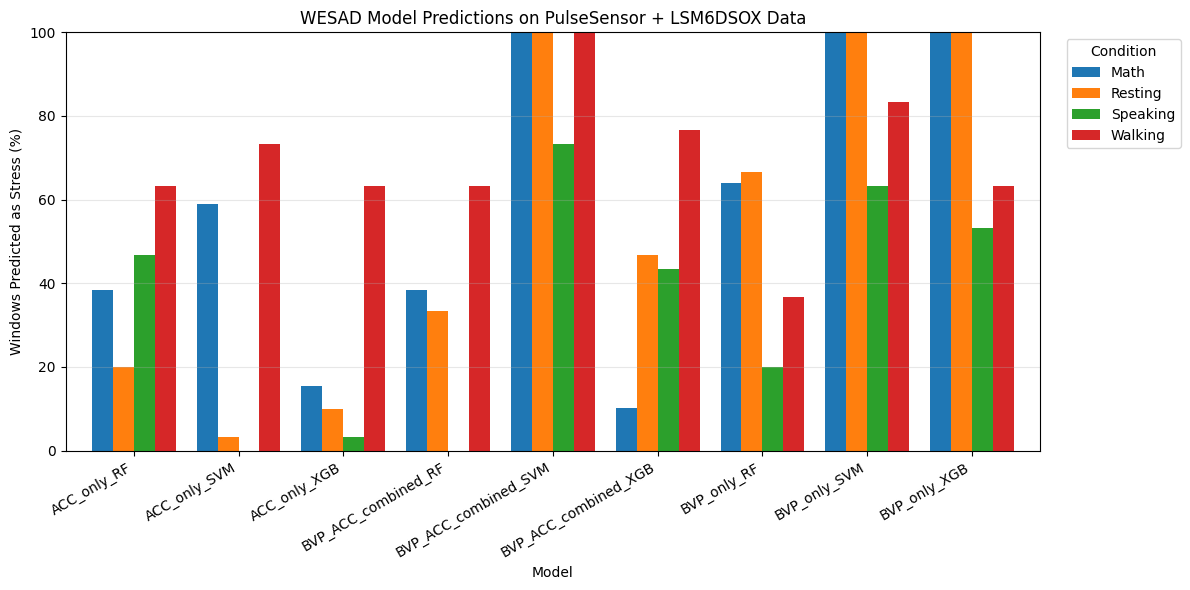

In [23]:
import matplotlib.pyplot as plt

# ============================================================
# Plot stress prediction percentages
# ============================================================

plot_df = prediction_summary.pivot(
    index="model",
    columns="condition",
    values="Stress_Percentage"
)

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "WESAD Model Predictions on PulseSensor + LSM6DSOX Data"
)

ax.set_xlabel("Model")
ax.set_ylabel("Windows Predicted as Stress (%)")

ax.set_ylim(0, 100)

ax.legend(
    title="Condition",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Visualize stress probability over time

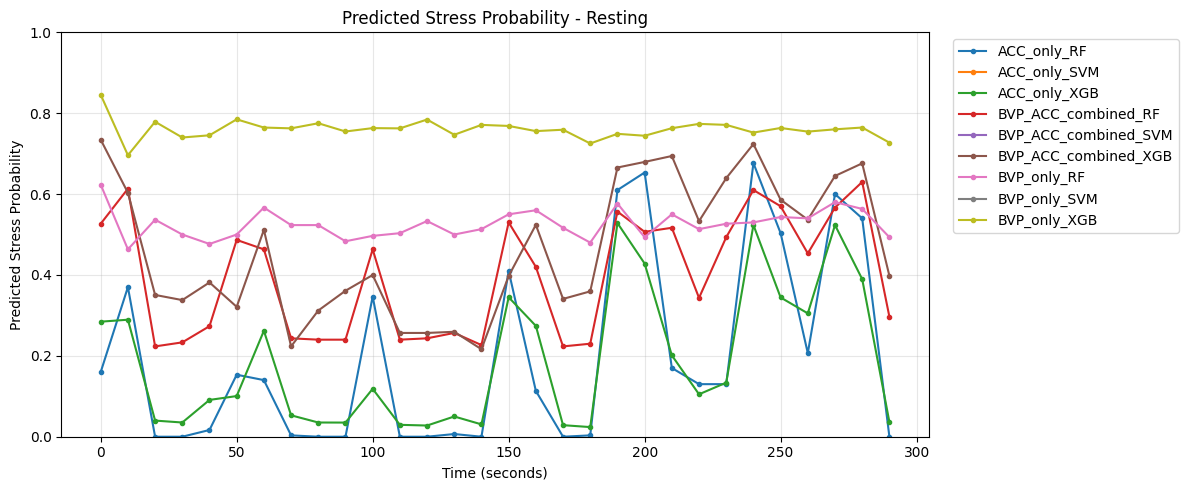

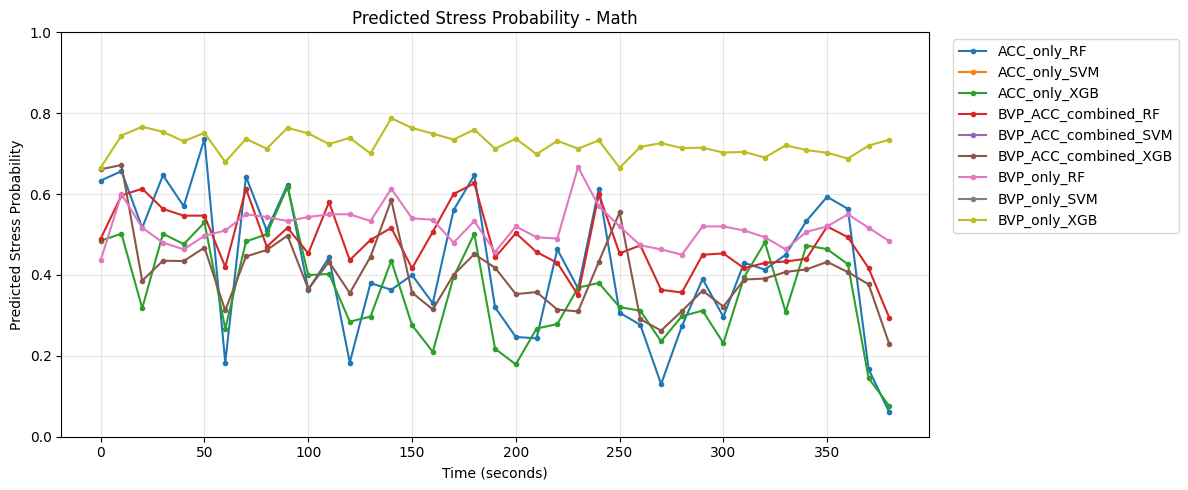

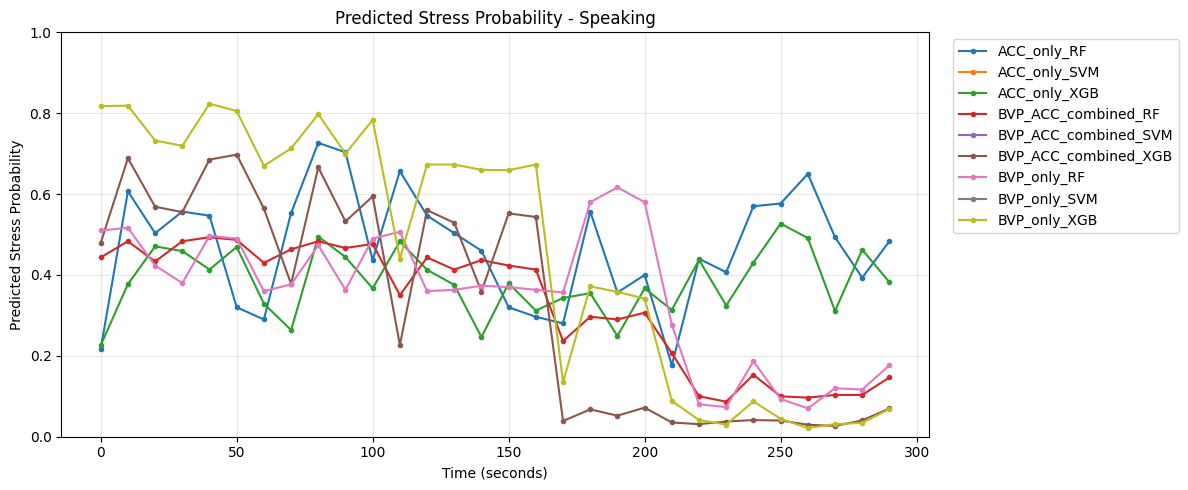

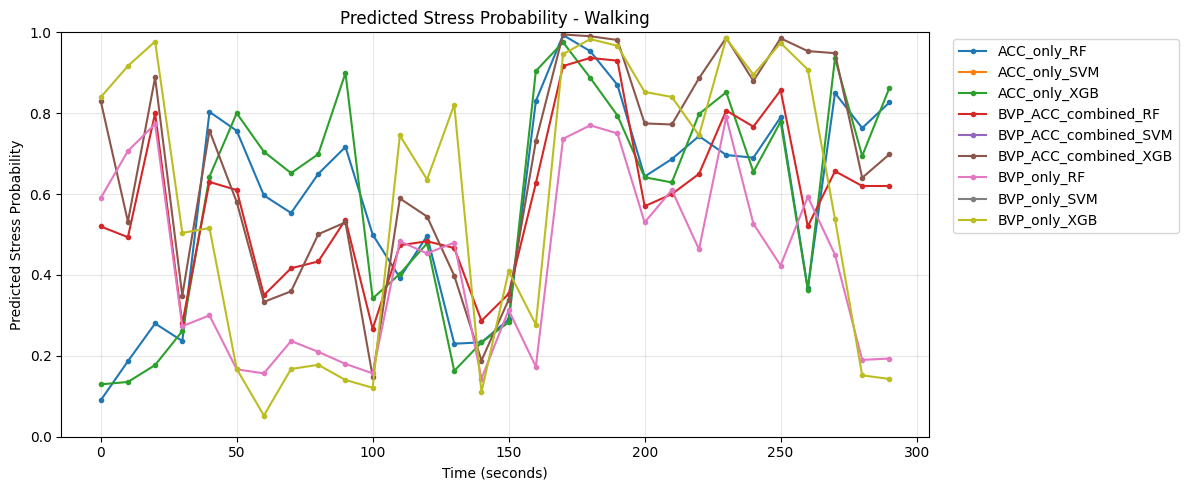

In [24]:
# ============================================================
# Plot stress probability over time
# ============================================================

for condition in ["Resting", "Math", "Speaking", "Walking"]:

    condition_df = predictions_df[
        predictions_df["condition"] == condition
    ]

    if condition_df.empty:
        continue

    plt.figure(figsize=(12, 5))

    for model_key in sorted(
        condition_df["model"].unique()
    ):

        model_df = condition_df[
            condition_df["model"] == model_key
        ]

        plt.plot(
            model_df["window_start_sec"],
            model_df["stress_probability"],
            marker="o",
            markersize=3,
            label=model_key
        )

    plt.title(
        f"Predicted Stress Probability - {condition}"
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Predicted Stress Probability")

    plt.ylim(0, 1)

    plt.grid(alpha=0.3)
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

# Save all external testing results

In [25]:
# ============================================================
# Save all external testing results
# ============================================================

OUTPUT_DIR = "/content/External_Test_Results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Save all window-level predictions
predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "External_Test_All_Predictions.csv"
    ),
    index=False
)

# Save summary
prediction_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "External_Test_Prediction_Summary.csv"
    ),
    index=False
)

# Save stress percentage comparison
stress_percentage_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "External_Test_Stress_Percentage.csv"
    )
)

# Save feature files for each condition
for condition, df in external_features.items():

    df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"External_Features_{condition}.csv"
        ),
        index=False
    )

print("All external testing results saved.")

print("\nFiles:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

All external testing results saved.

Files:
External_Features_Math.csv
External_Features_Resting.csv
External_Features_Speaking.csv
External_Features_Walking.csv
External_Test_All_Predictions.csv
External_Test_Prediction_Summary.csv
External_Test_Stress_Percentage.csv


# Download the results

In [26]:
import shutil
from google.colab import files

ZIP_PATH = "/content/External_Test_Results.zip"

shutil.make_archive(
    "/content/External_Test_Results",
    "zip",
    OUTPUT_DIR
)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>